#1.Cleaning

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('transactions.csv')

In [4]:
df.describe

<bound method NDFrame.describe of        index                   City       Date  Card Type Exp Type Gender  \
0          0           Delhi, India  29-Oct-14       Gold    Bills      F   
1          1  Greater Mumbai, India  22-Aug-14   Platinum    Bills      F   
2          2       Bengaluru, India  27-Aug-14     Silver    Bills      F   
3          3  Greater Mumbai, India  12-Apr-14  Signature    Bills      F   
4          4       Bengaluru, India   5-May-15       Gold    Bills      F   
...      ...                    ...        ...        ...      ...    ...   
26047  26047         Kolkata, India  22-Jun-14     Silver   Travel      F   
26048  26048            Pune, India   3-Aug-14  Signature   Travel      M   
26049  26049       Hyderabad, India  16-Jan-15     Silver   Travel      M   
26050  26050          Kanpur, India  14-Sep-14     Silver   Travel      M   
26051  26051       Hyderabad, India  19-Oct-13  Signature    Bills      M   

       Amount  
0       82475  
1       3

In [5]:
df.isnull().sum()

index        0
City         0
Date         0
Card Type    0
Exp Type     0
Gender       0
Amount       0
dtype: int64

In [8]:
df.duplicated().sum

<bound method Series.sum of 0        False
1        False
2        False
3        False
4        False
         ...  
26047    False
26048    False
26049    False
26050    False
26051    False
Length: 26052, dtype: bool>

In [11]:
df.head(5)

,index,City,Date,Card Type,Exp Type,Gender,Amount
0,0,"Delhi, India",29-Oct-14,Gold,Bills,F,82475
1,1,"Greater Mumbai, India",22-Aug-14,Platinum,Bills,F,32555
2,2,"Bengaluru, India",27-Aug-14,Silver,Bills,F,101738
3,3,"Greater Mumbai, India",12-Apr-14,Signature,Bills,F,123424
4,4,"Bengaluru, India",5-May-15,Gold,Bills,F,171574


In [12]:
df.tail(5)

,index,City,Date,Card Type,Exp Type,Gender,Amount
26047,26047,"Kolkata, India",22-Jun-14,Silver,Travel,F,128191
26048,26048,"Pune, India",3-Aug-14,Signature,Travel,M,246316
26049,26049,"Hyderabad, India",16-Jan-15,Silver,Travel,M,265019
26050,26050,"Kanpur, India",14-Sep-14,Silver,Travel,M,88174
26051,26051,"Hyderabad, India",19-Oct-13,Signature,Bills,M,184410


In [13]:
if 'index' in df.columns:
    df = df.drop(columns=['index'])

In [14]:
text_cols = ['City', 'Card Type', 'Exp Type', 'Gender']
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

In [15]:
if 'City' in df.columns:
    df['City'] = df['City'].str.split(',').str[0]

In [16]:
if 'Date' in df.columns:
    df['Date'] = df['Date'].str.strip()
    df['Date'] = pd.to_datetime(df['Date'], format='%d-%b-%y', errors='coerce')

In [17]:
if 'Amount' in df.columns:
    # Coerces errors to NaN if any text characters are mixed into the numerical column
    df['Amount'] = pd.to_numeric(df['Amount'], errors='coerce')

In [19]:
print("\n--- Missing Values Count ---")
print(df.isnull().sum())


--- Missing Values Count ---
City         0
Date         0
Card Type    0
Exp Type     0
Gender       0
Amount       0
dtype: int64


In [20]:
df = df.dropna(subset=['Date', 'Amount'])

In [21]:
duplicate_count = df.duplicated().sum()
print(f"\nRemoved {duplicate_count} duplicate rows.")
df = df.drop_duplicates()


Removed 0 duplicate rows.


In [22]:
print("\n--- Cleaned Data Info ---")
print(df.info())


--- Cleaned Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26052 entries, 0 to 26051
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   City       26052 non-null  object        
 1   Date       26052 non-null  datetime64[ns]
 2   Card Type  26052 non-null  object        
 3   Exp Type   26052 non-null  object        
 4   Gender     26052 non-null  object        
 5   Amount     26052 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 1.2+ MB
None


In [23]:
df.to_csv('cleaned_transactions.csv', index=False)
print("\nCleaned file saved successfully as 'cleaned_transactions.csv'!")


Cleaned file saved successfully as 'cleaned_transactions.csv'!


#2.Visualization

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

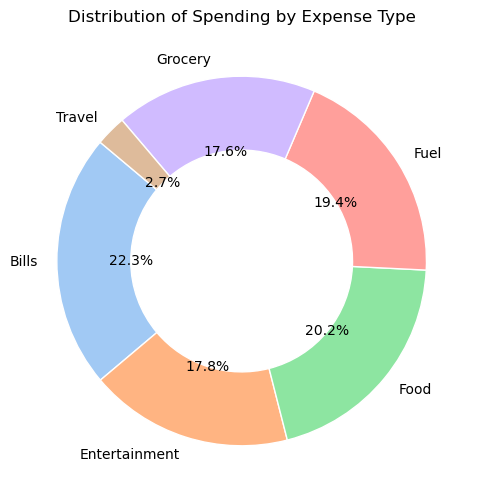

In [47]:
df_exp = df.groupby('Exp Type')['Amount'].sum()

plt.figure(figsize=(6, 6))
plt.pie(df_exp, labels=df_exp.index, autopct='%1.1f%%', startangle=140, 
        colors=sns.color_palette('pastel'), wedgeprops=dict(width=0.4, edgecolor='w')) # Creates a donut chart
plt.title('Distribution of Spending by Expense Type')
plt.savefig("Distribution of spending by expense type.png", dpi=300)
plt.show()

C:\Users\91630\AppData\Local\Temp\ipykernel_21072\1304536639.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Card Type', y='Amount', palette='Set2')


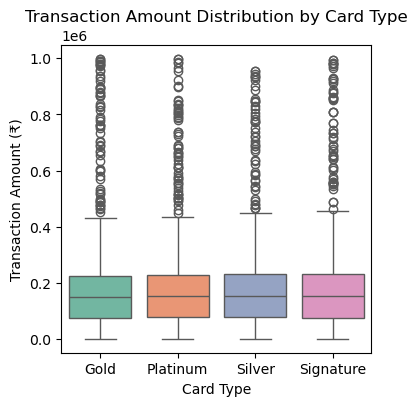

In [48]:
plt.figure(figsize=(4, 4))
# Using log scale if amounts vary drastically, or filtering out extreme outliers
sns.boxplot(data=df, x='Card Type', y='Amount', palette='Set2')
plt.title('Transaction Amount Distribution by Card Type')
plt.xlabel('Card Type')
plt.ylabel('Transaction Amount (₹)')
plt.savefig("Transaction Amount Distribution by card Type.png", dpi=300)
plt.show()

#3.Prediction models

In [31]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [33]:
df = pd.read_csv("cleaned_transactions.csv")
df['Date'] = pd.to_datetime(df['Date'])

In [34]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6
df['Day'] = df['Date'].dt.day

In [35]:
features = ['City', 'Card Type', 'Exp Type', 'Gender', 'Year', 'Month', 'DayOfWeek', 'Day']
X = df[features]
y = df['Amount']

In [40]:
# 4. Split data into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
# 5. Preprocessing for Categorical Variables
# Machine learning models require numeric inputs. OneHotEncoder translates text profiles to binary flags.
categorical_features = ['City', 'Card Type', 'Exp Type', 'Gender']
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough' # Keep our numerical Date flags untouched
)

In [42]:
# 6. Build the Machine Learning Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

In [43]:
# 7. Train the Model
print("Training the predictive model... Please wait.")
model_pipeline.fit(X_train, y_train)
print("Model training complete!")

Training the predictive model... Please wait.
Model training complete!


In [44]:
# 8. Evaluate Model Performance
y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Evaluation Metrics ---")
print(f"Mean Absolute Error (MAE): ₹{mae:.2f}")
print(f"R² Score: {r2:.4f}")


--- Model Evaluation Metrics ---
Mean Absolute Error (MAE): ₹85144.15
R² Score: -0.1521


In [45]:
# 9. Quick Simulation: Making a Live Prediction
# Input dummy criteria to see what the model estimates
sample_customer = pd.DataFrame([{
    'City': 'Bengaluru',
    'Card Type': 'Gold',
    'Exp Type': 'Food',
    'Gender': 'F',
    'Year': 2026,
    'Month': 10,
    'DayOfWeek': 5, # Saturday
    'Day': 31
}])

predicted_spend = model_pipeline.predict(sample_customer)
print(f"\n🔮 Predicted spend structure for sample customer criteria: ₹{predicted_spend[0]:.2f}")


🔮 Predicted spend structure for sample customer criteria: ₹149090.04


#4.DashBoard Creation

2026-10-31 16:44:04.280 
  command:

    streamlit run C:\Users\91630\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-31 16:44:04.280 No runtime found, using MemoryCacheStorageManager
2026-10-31 16:44:04.280 No runtime found, using MemoryCacheStorageManager
C:\Users\91630\AppData\Local\Temp\ipykernel_21072\2927722269.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_spend.values, y=city_spend.index, ax=ax, palette='viridis')
2026-10-31 16:44:31.092 Session state does not function when running a script without `streamlit run`


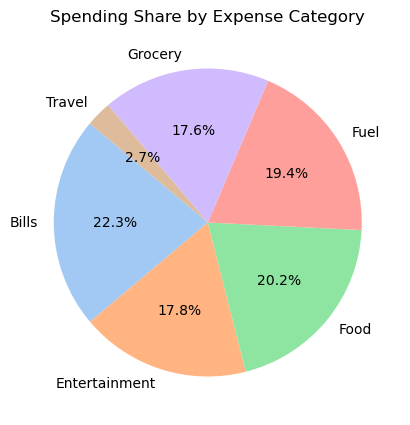

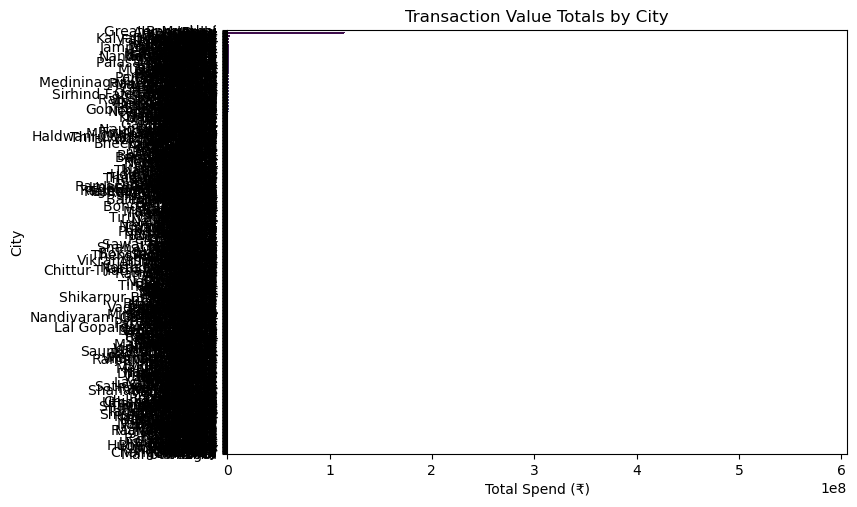

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# --- Page Layout Configuration ---
st.set_page_config(page_title="Credit Card Analytics Dashboard", layout="wide")
st.title("💳 Credit Card Transactions & Spend Prediction Dashboard")

# --- 1. Load Data ---
@st.cache_data
def load_data():
    # Read the data from your CSV file
    df = pd.read_csv('cleaned_transactions.csv')
    df['Date'] = pd.to_datetime(df['Date'])
    df['Year'] = df['Date'].dt.year
    df['Month'] = df['Date'].dt.month
    df['DayOfWeek'] = df['Date'].dt.dayofweek
    df['Day'] = df['Date'].dt.day
    return df

try:
    df = load_data()
except FileNotFoundError:
    st.error("❌ 'cleaned_transactions.csv' not found. Please place it in this directory.")
    st.stop()

# --- 2. Train ML Model Pipeline (Cached for Performance) ---
@st.cache_resource
def train_model(data):
    features = ['City', 'Card Type', 'Exp Type', 'Gender', 'Year', 'Month', 'DayOfWeek', 'Day']
    X = data[features]
    y = data['Amount']
    
    categorical_features = ['City', 'Card Type', 'Exp Type', 'Gender']
    preprocessor = ColumnTransformer(
        transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)],
        remainder='passthrough'
    )
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1))
    ])
    pipeline.fit(X, y)
    return pipeline

model = train_model(df)

# --- Sidebar Filters ---
st.sidebar.header("🔍 Global Data Filters")
selected_city = st.sidebar.multiselect("Select Cities", options=df['City'].unique(), default=df['City'].unique())
selected_card = st.sidebar.multiselect("Select Card Types", options=df['Card Type'].unique(), default=df['Card Type'].unique())

# Filtered View
filtered_df = df[(df['City'].isin(selected_city)) & (df['Card Type'].isin(selected_card))]

# --- Layout: Key Performance Metrics ---
col1, col2, col3 = st.columns(3)
with col1:
    st.metric("Total Spending Volume", f"₹{filtered_df['Amount'].sum():,.2f}")
with col2:
    st.metric("Total Transactions", f"{filtered_df.shape[0]:,}")
with col3:
    st.metric("Average Transaction Value", f"₹{filtered_df['Amount'].mean():,.2f}")

st.markdown("---")

# --- Layout: Main Analytics Visualisations ---
tab1, tab2 = st.tabs(["📊 Spending Analytics Trends", "🔮 Predictive AI Spends Engine"])

with tab1:
    st.subheader("Historical Transaction Breakdowns")
    chart_col1, chart_col2 = st.columns(2)
    
    with chart_col1:
        # Pie Chart: Spending Share by Expense Type
        fig, ax = plt.subplots(figsize=(6, 5))
        exp_shares = filtered_df.groupby('Exp Type')['Amount'].sum()
        ax.pie(exp_shares, labels=exp_shares.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
        ax.set_title("Spending Share by Expense Category")
        st.pyplot(fig)
        
    with chart_col2:
        # Bar Chart: Spending Breakdown by City
        fig, ax = plt.subplots(figsize=(8, 5.5))
        city_spend = filtered_df.groupby('City')['Amount'].sum().sort_values(ascending=False)
        sns.barplot(x=city_spend.values, y=city_spend.index, ax=ax, palette='viridis')
        ax.set_title("Transaction Value Totals by City")
        ax.set_xlabel("Total Spend (₹)")
        st.pyplot(fig)

with tab2:
    st.subheader("Predict Customer Transaction Value")
    st.write("Input transactional metadata attributes below to predict expected customer credit spending limits.")
    
    # User Feature Inputs for Live Model Scoring
    p_col1, p_col2, p_col3, p_col4 = st.columns(4)
    with p_col1:
        input_city = st.selectbox("Customer City Location", options=df['City'].unique())
    with p_col2:
        input_card = st.selectbox("Card Category tier", options=df['Card Type'].unique())
    with p_col3:
        input_exp = st.selectbox("Target Expense Area", options=df['Exp Type'].unique())
    with p_col4:
        input_gender = st.radio("Gender Profile", options=df['Gender'].unique(), horizontal=True)
        
    # Execute Model Pipeline Prediction on User Metrics
    if st.button("🔮 Calculate Estimated Spending Target"):
        # Synthesize temporary feature set vector matrix
        mock_profile = pd.DataFrame([{
            'City': input_city, 'Card Type': input_card, 'Exp Type': input_exp, 'Gender': input_gender,
            'Year': 2026, 'Month': 10, 'DayOfWeek': 5, 'Day': 31
        }])
        
        prediction = model.predict(mock_profile)[0]
        st.success(f"🎯 **Predicted Estimated Transaction Cost Bounds:** ₹{prediction:,.2f}")